# Student Performance Prediction

## 01. Load Data

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('student_performance.csv')
df.head()

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,1,18.5,95.6,3.8,97.9,A
1,2,14.0,80.0,2.5,83.9,B
2,3,19.5,86.3,5.3,100.0,A
3,4,25.7,70.2,7.0,100.0,A
4,5,13.4,81.9,6.9,92.0,A


## 02. Data Understanding

In [3]:
df.shape

(1000000, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   student_id               1000000 non-null  int64  
 1   weekly_self_study_hours  1000000 non-null  float64
 2   attendance_percentage    1000000 non-null  float64
 3   class_participation      1000000 non-null  float64
 4   total_score              1000000 non-null  float64
 5   grade                    1000000 non-null  str    
dtypes: float64(4), int64(1), str(1)
memory usage: 46.7 MB


In [5]:
df.describe().round(2)

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score
count,1000000.00,1000000.00,1000000.00,1000000.00,1000000.00
mean,500000.50,15.03,84.71,5.99,84.28
std,288675.28,6.90,9.42,1.96,15.43
min,1.00,0.00,50.00,0.00,9.40
25%,250000.75,10.30,78.30,4.70,73.90
50%,500000.50,15.00,85.00,6.00,87.50
75%,750000.25,19.70,91.80,7.30,100.00
max,1000000.00,40.00,100.00,10.00,100.00


## 03. Data Quality

In [6]:
df.isnull().sum()

student_id                 0
weekly_self_study_hours    0
attendance_percentage      0
class_participation        0
total_score                0
grade                      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["student_id"].duplicated().sum()

np.int64(0)

In [9]:
assert not df[['weekly_self_study_hours', 'attendance_percentage', 'class_participation', 'total_score']].isna().any().any()
assert df['student_id'].is_unique
assert df['total_score'].between(0, 100).all()

### Insight
No missing values or duplicate student IDs were found.

## 04. EDA — Score Distribution

In [10]:
import matplotlib.pyplot as plt

In [11]:
full_score_percentage = (df["total_score"] == 100).mean() * 100

print(f"Students with 100% :",full_score_percentage)

Students with 100% : 26.8121


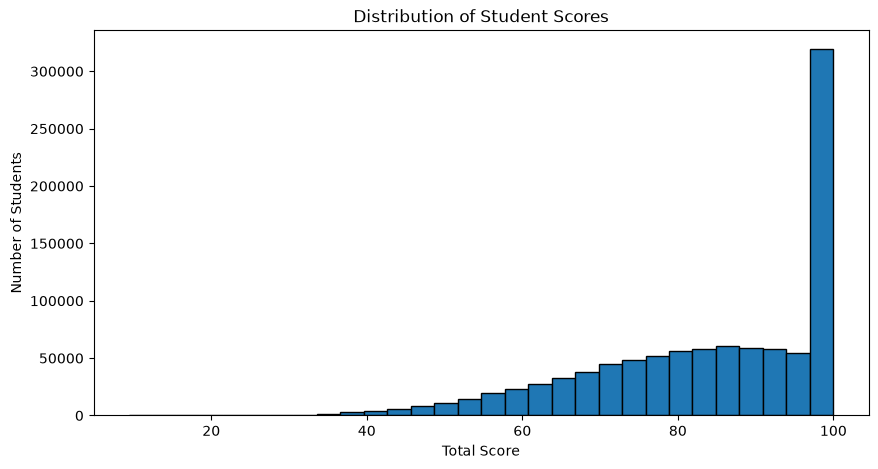

In [12]:
plt.figure(figsize=(10,5))

plt.hist(
    df["total_score"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Student Scores")
plt.xlabel("Total Score")
plt.ylabel("Number of Students")
plt.show()

### Insight
Scores are concentrated at the upper end, with about 26.8% of students scoring 100.

## 05. EDA — Numerical Features

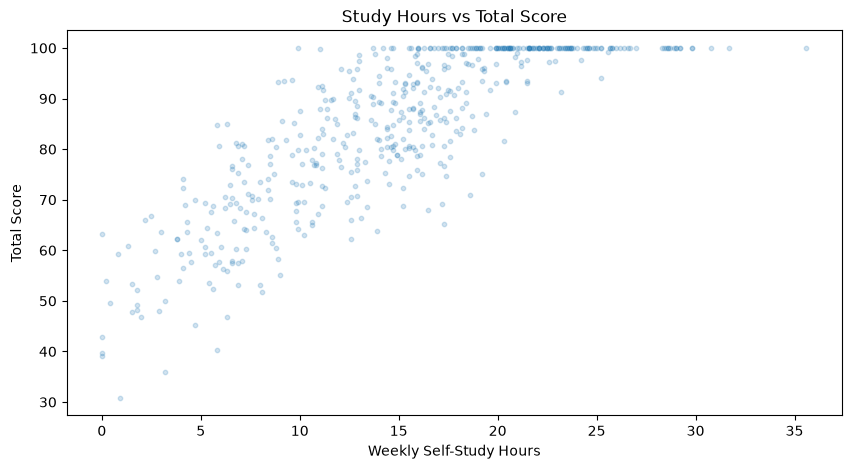

In [13]:
sample_df=df.sample(n=500, random_state=42)

plt.figure(figsize=(10,5))

plt.scatter(
    sample_df["weekly_self_study_hours"],
    sample_df["total_score"],
    alpha=0.2,
    s=10
)
plt.title("Study Hours vs Total Score")
plt.xlabel("Weekly Self-Study Hours")
plt.ylabel("Total Score")

plt.show()

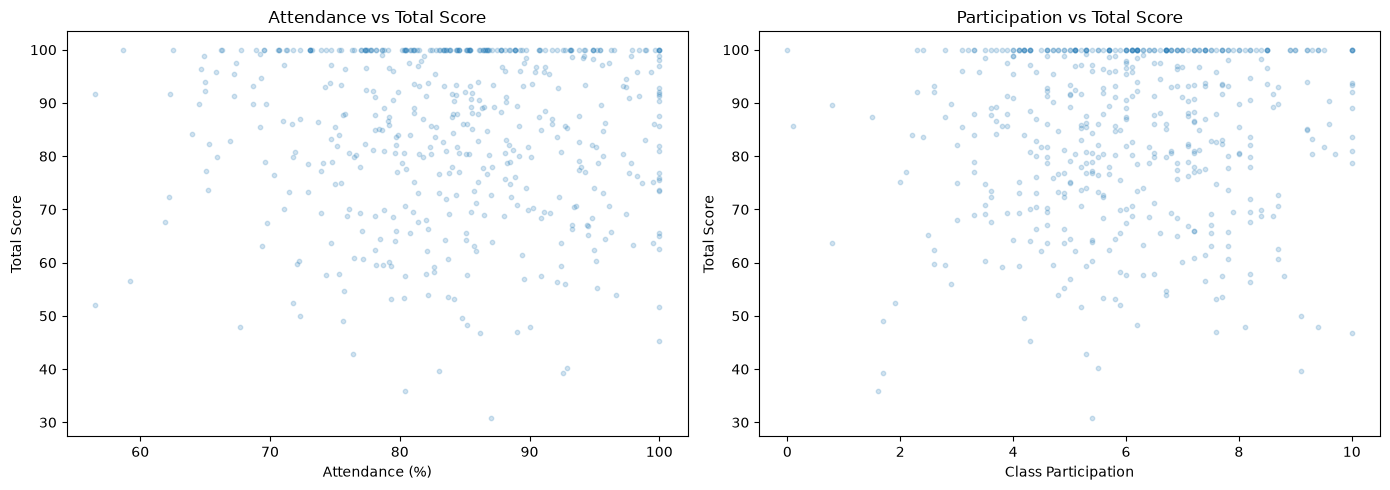

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    sample_df["attendance_percentage"],
    sample_df["total_score"],
    alpha=0.2,
    s=10
)
axes[0].set_title("Attendance vs Total Score")
axes[0].set_xlabel("Attendance (%)")
axes[0].set_ylabel("Total Score")

axes[1].scatter(
    sample_df["class_participation"],
    sample_df["total_score"],
    alpha=0.2,
    s=10
)
axes[1].set_title("Participation vs Total Score")
axes[1].set_xlabel("Class Participation")
axes[1].set_ylabel("Total Score")

plt.tight_layout()
plt.show()

### Insight
Study hours show a clear positive relationship with scores. Attendance and participation show weaker patterns.

## 06. Correlation

In [15]:
columns = [
    "weekly_self_study_hours",
    "attendance_percentage",
    "class_participation",
    "total_score"
]

correlations = df[columns].corr()

correlations["total_score"].sort_values(ascending=False)

total_score                1.000000
weekly_self_study_hours    0.812241
class_participation        0.000684
attendance_percentage     -0.001014
Name: total_score, dtype: float64

In [16]:
import seaborn as sns

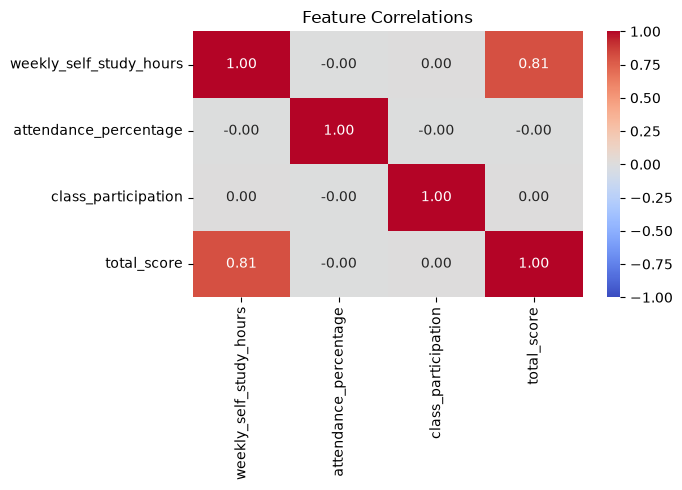

In [17]:
plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Feature Correlations')
plt.tight_layout()
plt.show()

### Insight
Study hours have the strongest linear correlation with total score. Student ID and grade are excluded from the inputs.

## 07. Train / Validation / Test Split

In [18]:
X = df[[
    'weekly_self_study_hours',
    'attendance_percentage',
    'class_participation'
]]
y = df['total_score']

In [19]:
from sklearn.model_selection import train_test_split

X_development, X_final_test, y_development, y_final_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_development, y_development, test_size=0.2, random_state=42
)

print('Training:', X_fit.shape)
print('Validation:', X_validation.shape)
print('Final test:', X_final_test.shape)

Training: (640000, 3)
Validation: (160000, 3)
Final test: (200000, 3)


### Insight
Models are compared on validation data. The final test split is used only after model selection in this run.

## 08. Baseline

In [20]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_fit, y_fit)
baseline_predictions = baseline.predict(X_validation)
baseline_mae = mean_absolute_error(y_validation, baseline_predictions)
print(f'Baseline Validation MAE: {baseline_mae:.3f}')

Baseline Validation MAE: 12.908


## 09. Linear Regression

In [21]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_fit,y_fit)

predictions=model.predict(X_validation)

model_mae=mean_absolute_error(y_validation, predictions)

print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Linear Regression MAE: {model_mae:.2f}")

Baseline MAE: 12.91
Linear Regression MAE: 7.16


In [22]:
comparison=X_validation.copy()

comparison['actual_score']=y_validation
comparison['predicted_score']=predictions

comparison['absolute_error']=(comparison['actual_score'] - comparison['predicted_score']).abs()

comparison.head(10).round(2)

,weekly_self_study_hours,attendance_percentage,class_participation,actual_score,predicted_score,absolute_error
866857,19.2,100.0,6.2,95.6,91.84,3.76
825981,8.6,81.4,3.3,84.7,72.60,12.10
456670,14.2,88.6,5.0,70.2,82.77,12.57
350242,23.9,78.1,6.5,100.0,100.37,0.37
732615,20.3,88.0,3.3,96.7,93.85,2.85
124433,10.9,84.3,4.4,99.2,76.78,22.42
990789,13.9,85.7,5.9,79.1,82.22,3.12
319241,14.6,81.8,4.1,77.3,83.50,6.20
107248,26.2,76.6,5.7,100.0,104.55,4.55
985554,13.1,86.9,5.7,85.1,80.77,4.33


In [23]:
print(f"Lowest prediction: {predictions.min():.2f}")
print(f"Highest prediction: {predictions.max():.2f}")

Lowest prediction: 56.96
Highest prediction: 129.62


In [24]:
import numpy as np

In [25]:
clipped_predictions = np.clip(predictions, 0, 100)

clipped_mae = mean_absolute_error(
    y_validation,
    clipped_predictions
)

print(f"Original MAE: {model_mae:.2f}")
print(f"Clipped MAE: {clipped_mae:.2f}")
print(f"Predictions above 100: {(predictions > 100).sum()}")

Original MAE: 7.16
Clipped MAE: 6.52
Predictions above 100: 17116


### Insight
Linear Regression can predict scores above 100. Predictions are clipped to the valid score range.

## 10. Decision Tree

In [26]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_fit, y_fit)
tree_val_predictions = tree_model.predict(X_validation)
tree_val_mae = mean_absolute_error(y_validation, tree_val_predictions)

print(f'Linear Regression Validation MAE: {clipped_mae:.3f}')
print(f'Decision Tree Validation MAE: {tree_val_mae:.3f}')

Linear Regression Validation MAE: 6.522
Decision Tree Validation MAE: 6.112


In [27]:
tree_train_predictions = tree_model.predict(X_fit)

tree_train_mae = mean_absolute_error(
    y_fit,
    tree_train_predictions
)

print(f"Decision Tree Training MAE: {tree_train_mae:.2f}")
print(f"Decision Tree Validation MAE: {tree_val_mae:.2f}")

Decision Tree Training MAE: 6.12
Decision Tree Validation MAE: 6.11


### Tree Depth Experiment

In [28]:
results = []

for depth in [2, 3, 5, 7, 10, 15]:
    candidate = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    candidate.fit(X_fit, y_fit)

    train_mae = mean_absolute_error(
        y_fit,
        candidate.predict(X_fit)
    )

    validation_mae = mean_absolute_error(
        y_validation,
        candidate.predict(X_validation)
    )

    results.append({
        "max_depth": depth,
        "train_mae": train_mae,
        "validation_mae": validation_mae
    })

depth_results = pd.DataFrame(results)

depth_results.round(3)

,max_depth,train_mae,validation_mae
0,2,6.834,6.828
1,3,6.288,6.280
2,5,6.119,6.112
3,7,6.107,6.106
4,10,6.083,6.123
5,15,5.828,6.282


### Feature Importance

In [29]:
feature_importance = pd.Series(
    tree_model.feature_importances_,
    index=X_fit.columns
).sort_values(ascending=False)

print(feature_importance.round(4))

weekly_self_study_hours    1.0
attendance_percentage      0.0
class_participation        0.0
dtype: float64


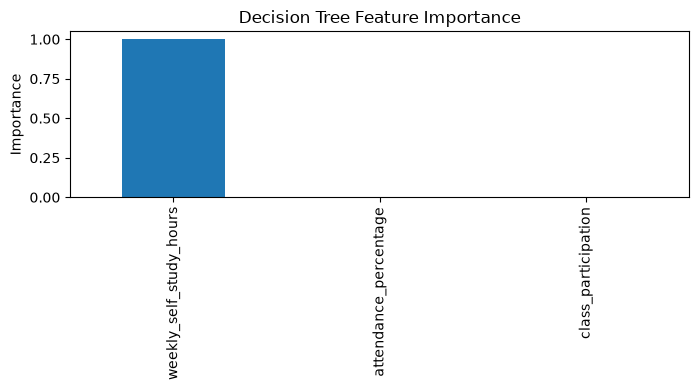

In [30]:
feature_importance.plot(kind='bar', figsize=(7, 4))
plt.ylabel('Importance')
plt.title('Decision Tree Feature Importance')
plt.tight_layout()
plt.show()

### Insight
Deeper trees can reduce training error without improving validation error. Study hours dominate this shallow tree.

### Study Hours Only

In [31]:
study_only_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

study_only_model.fit(
    X_fit[["weekly_self_study_hours"]],
    y_fit
)

study_only_predictions = study_only_model.predict(
    X_validation[["weekly_self_study_hours"]]
)

study_only_mae = mean_absolute_error(
    y_validation,
    study_only_predictions
)

print(f"Three features MAE: {tree_val_mae:.3f}")
print(f"Study hours only MAE: {study_only_mae:.3f}")

Three features MAE: 6.112
Study hours only MAE: 6.112


## 11. Decision Tree Error Analysis

In [32]:
error_analysis=pd.DataFrame({
    "actual_score":y_validation,
    "predicted_score": study_only_predictions
})

error_analysis["absolute_error"]=(error_analysis["actual_score"]-error_analysis["predicted_score"]).abs()

error_analysis["score_group"] = pd.cut(
    error_analysis["actual_score"],
    bins=[0, 60, 80, 100],
    labels=["60 or below", "60 to 80", "Above 80"],
    include_lowest=True
)

error_summary = error_analysis.groupby(
    "score_group",
    observed=True
).agg(
    students_count=("absolute_error", "size"),
    mae=("absolute_error", "mean")
)

error_summary.round(2)

,students_count,mae
score_group,,
60 or below,13735,10.42
60 to 80,43414,7.53
Above 80,102851,4.94


In [33]:
error_analysis["signed_error"] = (
    error_analysis["predicted_score"]
    - error_analysis["actual_score"]
)

direction_summary = error_analysis.groupby(
    "score_group",
    observed=True
).agg(
    mean_signed_error=("signed_error", "mean"),
    mae=("absolute_error", "mean")
)

direction_summary.round(2)

,mean_signed_error,mae
score_group,,
60 or below,9.45,10.42
60 to 80,3.59,7.53
Above 80,-2.81,4.94


In [34]:
errors = error_analysis["absolute_error"]

print(f"Median absolute error: {errors.median():.2f}")
print(f"90th percentile error: {errors.quantile(0.90):.2f}")
print(f"Errors above 15 points: {(errors > 15).mean() * 100:.2f}%")

Median absolute error: 4.67
90th percentile error: 13.94
Errors above 15 points: 7.84%


### Insight
Errors are larger for lower-scoring students. Grouping by actual scores is diagnostic and cannot be used as a prediction rule.

## 12. Random Forest

In [35]:
from sklearn.ensemble import RandomForestRegressor

forest_model=RandomForestRegressor(
    n_estimators=50,
    max_depth=7,
    random_state=42,
    n_jobs=2
)

forest_model.fit(X_fit,y_fit)

forest_val_predictions=forest_model.predict(X_validation)
forest_val_mae = mean_absolute_error(
    y_validation,
    forest_val_predictions
)

print(f"Decision Tree Validation MAE: {study_only_mae:.3f}")
print(f"Random Forest Validation MAE: {forest_val_mae:.3f}")

Decision Tree Validation MAE: 6.112
Random Forest Validation MAE: 6.103


## 13. Gradient Boosting Experiments

In [36]:
from sklearn.ensemble import HistGradientBoostingRegressor

study_features = ["weekly_self_study_hours"]

boosting_model = HistGradientBoostingRegressor(
    loss="absolute_error",
    max_iter=100,
    max_leaf_nodes=15,
    learning_rate=0.1,
    early_stopping=True,
    random_state=42
)

boosting_model.fit(
    X_fit[study_features],
    y_fit
)

boosting_predictions = boosting_model.predict(
    X_validation[study_features]
)

boosting_predictions = np.clip(boosting_predictions, 0, 100)

boosting_mae = mean_absolute_error(
    y_validation,
    boosting_predictions
)

print(f"Decision Tree MAE: {study_only_mae:.3f}")
print(f"Gradient Boosting MAE: {boosting_mae:.3f}")

Decision Tree MAE: 6.112
Gradient Boosting MAE: 5.923


In [37]:
comparison_results = []

for name, preds in [
    ("Decision Tree", study_only_predictions),
    ("Gradient Boosting", boosting_predictions)
]:
    errors = np.abs(y_validation.to_numpy() - preds)

    comparison_results.append({
        "model": name,
        "mae": errors.mean(),
        "90th_percentile_error": np.quantile(errors, 0.90),
        "errors_above_15_pct": (errors > 15).mean() * 100
    })

pd.DataFrame(comparison_results).round(3)

,model,mae,90th_percentile_error,errors_above_15_pct
0,Decision Tree,6.112,13.942,7.842
1,Gradient Boosting,5.923,14.192,8.413


In [38]:
group_comparison = error_analysis[
    ["actual_score", "score_group"]
].copy()

group_comparison["tree_error"] = np.abs(
    group_comparison["actual_score"] - study_only_predictions
)

group_comparison["boosting_error"] = np.abs(
    group_comparison["actual_score"] - boosting_predictions
)

group_results = group_comparison.groupby(
    "score_group",
    observed=True
).agg(
    students_count=("actual_score", "size"),
    tree_mae=("tree_error", "mean"),
    boosting_mae=("boosting_error", "mean")
)

group_results["improvement"] = (
    group_results["tree_mae"] - group_results["boosting_mae"]
)

group_results.round(3)

,students_count,tree_mae,boosting_mae,improvement
score_group,,,,
60 or below,13735,10.422,10.440,-0.018
60 to 80,43414,7.532,7.705,-0.173
Above 80,102851,4.937,4.567,0.369


In [39]:
boosting_squared = HistGradientBoostingRegressor(
    loss="squared_error",
    max_iter=100,
    max_leaf_nodes=15,
    learning_rate=0.1,
    early_stopping=True,
    random_state=42
)

boosting_squared.fit(
    X_fit[study_features],
    y_fit
)

squared_predictions = boosting_squared.predict(
    X_validation[study_features]
)

squared_predictions = np.clip(squared_predictions, 0, 100)

In [40]:
results = []

for name, preds in [
    ("Decision Tree", study_only_predictions),
    ("Boosting absolute error", boosting_predictions),
    ("Boosting squared error", squared_predictions)
]:
    errors = np.abs(y_validation.to_numpy() - preds)

    results.append({
        "model": name,
        "mae": errors.mean(),
        "90th_percentile_error": np.quantile(errors, 0.90),
        "errors_above_15_pct": (errors > 15).mean() * 100
    })

pd.DataFrame(results).round(3)

,model,mae,90th_percentile_error,errors_above_15_pct
0,Decision Tree,6.112,13.942,7.842
1,Boosting absolute error,5.923,14.192,8.413
2,Boosting squared error,6.104,13.857,7.742


### Insight
The lowest average error does not necessarily mean fewer large errors. Both are included in the comparison.

## 14. Model Comparison

In [41]:
from sklearn.metrics import mean_squared_error, r2_score

In [42]:
candidate_models = {
    'Linear Regression': (model, list(X.columns)),
    'Decision Tree': (tree_model, list(X.columns)),
    'Decision Tree — study only': (study_only_model, study_features),
    'Random Forest': (forest_model, list(X.columns)),
    'Boosting absolute error': (boosting_model, study_features),
    'Boosting squared error': (boosting_squared, study_features)
}

model_results = [{
    'Model': 'Baseline',
    'Train MAE': mean_absolute_error(y_fit, baseline.predict(X_fit)),
    'Validation MAE': baseline_mae,
    'RMSE': np.sqrt(mean_squared_error(y_validation, baseline_predictions)),
    'R2': r2_score(y_validation, baseline_predictions)
}]

for name, (candidate, features) in candidate_models.items():
    train_predictions = np.clip(candidate.predict(X_fit[features]), 0, 100)
    validation_predictions = np.clip(candidate.predict(X_validation[features]), 0, 100)
    model_results.append({
        'Model': name,
        'Train MAE': mean_absolute_error(y_fit, train_predictions),
        'Validation MAE': mean_absolute_error(y_validation, validation_predictions),
        'RMSE': np.sqrt(mean_squared_error(y_validation, validation_predictions)),
        'R2': r2_score(y_validation, validation_predictions)
    })

model_comparison = pd.DataFrame(model_results).sort_values('Validation MAE').reset_index(drop=True)
model_comparison.round(3)

,Model,Train MAE,Validation MAE,RMSE,R2
0,Boosting absolute error,5.934,5.923,8.291,0.711
1,Random Forest,6.105,6.103,8.188,0.718
2,Boosting squared error,6.110,6.104,8.187,0.718
3,Decision Tree — study only,6.119,6.112,8.195,0.717
4,Decision Tree,6.119,6.112,8.195,0.717
5,Linear Regression,6.519,6.522,8.588,0.690
6,Baseline,12.914,12.908,15.418,-0.000


### Insight
MAE is the primary selection metric. RMSE highlights larger errors, and R2 is not classification accuracy.

In [43]:
learned_results = model_comparison[model_comparison['Model'] != 'Baseline']
best_model_name = learned_results.iloc[0]['Model']
selected_model, selected_features = candidate_models[best_model_name]
print('Selected model:', best_model_name)
print('Selected features:', selected_features)

Selected model: Boosting absolute error
Selected features: ['weekly_self_study_hours']


## 15. Final Pipeline

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [45]:
preprocessor = ColumnTransformer(
    transformers=[('numeric', 'passthrough', selected_features)],
    remainder='drop'
)

In [46]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', selected_model)
])

pipeline.fit(X_fit, y_fit)
pipeline_predictions = np.clip(pipeline.predict(X_validation), 0, 100)
pipeline_mae = mean_absolute_error(y_validation, pipeline_predictions)

print(f'Pipeline Validation MAE: {pipeline_mae:.3f}')

Pipeline Validation MAE: 5.923


### Insight
The pipeline selects the required numeric columns by name. No encoding is needed, and tree models do not require scaling.

## 16. Cross-validation

In [47]:
from sklearn.model_selection import cross_val_score

In [48]:
X_cv = X_fit.sample(n=min(50000, len(X_fit)), random_state=42)
y_cv = y_fit.loc[X_cv.index]

cv_scores = cross_val_score(
    pipeline, X_cv, y_cv,
    cv=3, scoring='neg_mean_absolute_error', n_jobs=1
)

print('Cross-validation MAE:', -cv_scores)
print('Mean CV MAE:', -cv_scores.mean())

Cross-validation MAE: [5.92130861 5.94945397 5.89975475]
Mean CV MAE: 5.923505777218332


### Insight
Cross-validation uses a random sample of training data to keep runtime manageable. Scores are based on raw predictions.

## 17. Hyperparameter Tuning

In [49]:
from sklearn.model_selection import GridSearchCV

In [50]:
if best_model_name.startswith('Boosting'):
    param_grid = {
        'model__max_leaf_nodes': [7, 15],
        'model__learning_rate': [0.05, 0.1]
    }
elif best_model_name.startswith('Decision Tree'):
    param_grid = {
        'model__max_depth': [5, 7],
        'model__min_samples_leaf': [1, 10]
    }
elif best_model_name == 'Random Forest':
    param_grid = {
        'model__max_depth': [5, 7],
        'model__min_samples_leaf': [1, 10]
    }
else:
    param_grid = {'model__fit_intercept': [True, False]}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=1
)

grid_search.fit(X_cv, y_cv)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [7, 15]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [51]:
print('Best parameters:', grid_search.best_params_)
print('Best CV MAE:', -grid_search.best_score_)

Best parameters: {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15}
Best CV MAE: 5.923505777218332


In [52]:
best_pipeline = grid_search.best_estimator_
best_pipeline.fit(X_fit, y_fit)

tuned_predictions = np.clip(best_pipeline.predict(X_validation), 0, 100)
tuned_mae = mean_absolute_error(y_validation, tuned_predictions)

print(f'Original Pipeline Validation MAE: {pipeline_mae:.3f}')
print(f'Tuned Pipeline Validation MAE: {tuned_mae:.3f}')

if tuned_mae < pipeline_mae:
    final_pipeline = best_pipeline
else:
    final_pipeline = pipeline

Original Pipeline Validation MAE: 5.923
Tuned Pipeline Validation MAE: 5.923


### Insight
Tuning is retained only if it improves validation MAE. The final test is not used to choose parameters.

## 18. Final Test Evaluation

In [53]:
final_predictions = np.clip(final_pipeline.predict(X_final_test), 0, 100)
final_errors = np.abs(y_final_test.to_numpy() - final_predictions)

print(f'Final MAE: {mean_absolute_error(y_final_test, final_predictions):.3f}')
print(f'Final RMSE: {np.sqrt(mean_squared_error(y_final_test, final_predictions)):.3f}')
print(f'Final R2: {r2_score(y_final_test, final_predictions):.3f}')
print(f'90th percentile error: {np.quantile(final_errors, 0.90):.3f}')
print(f'Errors above 15 points: {(final_errors > 15).mean() * 100:.3f}%')

Final MAE: 5.919
Final RMSE: 8.303
Final R2: 0.710
90th percentile error: 14.208
Errors above 15 points: 8.428%


### Insight
This is an internal evaluation on a previously explored dataset. New student data is needed to assess real-world generalization.

## 19. Save Pipeline

In [54]:
import joblib

In [55]:
joblib.dump(final_pipeline, 'student_performance_pipeline.pkl')

['student_performance_pipeline.pkl']

## 20. New-student Prediction

In [56]:
loaded_pipeline = joblib.load('student_performance_pipeline.pkl')

new_student = pd.DataFrame({
    'weekly_self_study_hours': [15],
    'attendance_percentage': [90],
    'class_participation': [7]
})

predicted_score = loaded_pipeline.predict(new_student)[0]
predicted_score = np.clip(predicted_score, 0, 100)

print(f'Predicted score: {predicted_score:.2f}')

Predicted score: 87.64


In [57]:
new_students = pd.DataFrame({
    'weekly_self_study_hours': [0, 5, 10, 15, 20, 30, 40],
    'attendance_percentage': [90] * 7,
    'class_participation': [7] * 7
})

prediction_results = new_students.copy()
prediction_results['predicted_score'] = np.clip(loaded_pipeline.predict(new_students), 0, 100)
prediction_results.round(2)

,weekly_self_study_hours,attendance_percentage,class_participation,predicted_score
0,0,90,7,50.44
1,5,90,7,62.45
2,10,90,7,75.07
3,15,90,7,87.64
4,20,90,7,99.54
5,30,90,7,100.00
6,40,90,7,100.00


### Insight
Predictions are estimates within the observed data range, not guaranteed scores or evidence of a causal effect.